# Notebook 12 – CNN Visualization



In [1]:
import time
import numpy as np
import torch
from torch import nn
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.14.0+cpu | device: cpu


## Concept and interpret
Feature maps show spatial activations. Filter images show learned kernel weights but can be hard to interpret alone. Saliency estimates input sensitivity. Grad-CAM weights a convolutional layer's feature maps by gradients of a target score, applies ReLU, and resizes a heatmap. Early layers often respond to edges/simple patterns; middle layers to textures/shapes; deeper layers to higher-level combinations.

prediction/label: 0 0 torch.Size([1, 8, 8, 8]) torch.Size([1, 16, 4, 4])


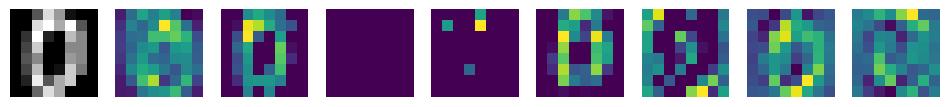

In [2]:
from sklearn.datasets import load_digits
from torch.utils.data import DataLoader,TensorDataset
import matplotlib.pyplot as plt
d=load_digits(); x=torch.tensor(d.images,dtype=torch.float32).unsqueeze(1)/16; y=torch.tensor(d.target,dtype=torch.long); loader=DataLoader(TensorDataset(x,y),128,shuffle=True)
class VizCNN(nn.Module):
 def __init__(self):
  super().__init__(); self.conv1=nn.Conv2d(1,8,3,padding=1); self.conv2=nn.Conv2d(8,16,3,padding=1); self.pool=nn.MaxPool2d(2); self.fc=nn.Linear(64,10)
 def forward(self,x):
  self.a1=torch.relu(self.conv1(x)); z=self.pool(self.a1); self.a2=torch.relu(self.conv2(z)); z=self.pool(self.a2); return self.fc(z.flatten(1))
m=VizCNN().to(device); opt=torch.optim.Adam(m.parameters(),lr=1e-3)
for _ in range(2):
 m.train()
 for xb,yb in loader:
  xb,yb=xb.to(device),yb.to(device); opt.zero_grad(); loss=nn.functional.cross_entropy(m(xb),yb); loss.backward(); opt.step()
m.eval(); sample=x[:1].to(device); logits=m(sample); print('prediction/label:',logits.argmax(1).item(),y[0].item(),m.a1.shape,m.a2.shape)
fig,axes=plt.subplots(1,9,figsize=(12,2)); axes[0].imshow(sample[0,0].detach().cpu(),cmap='gray')
for i,ax in enumerate(axes[1:]): ax.imshow(m.a1[0,i].detach().cpu(),cmap='viridis')
for ax in axes: ax.axis('off')
plt.show()

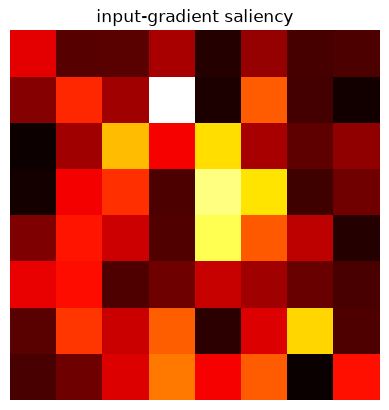

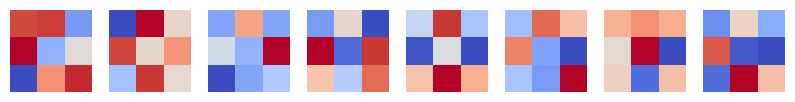

In [3]:
sample.requires_grad_(True); m.zero_grad(); target=m(sample).argmax(1).item(); m(sample)[0,target].backward()
saliency=sample.grad.abs().max(dim=1).values[0].detach().cpu(); plt.imshow(saliency,cmap='hot'); plt.title('input-gradient saliency'); plt.axis('off'); plt.show()
filters=m.conv1.weight.detach().cpu(); fig,axes=plt.subplots(1,8,figsize=(10,2))
for i,ax in enumerate(axes): ax.imshow(filters[i,0],cmap='coolwarm'); ax.axis('off')
plt.show()
# Grad-CAM: average target-score gradients per channel, weight late feature maps, ReLU, resize/overlay.

## Responsible interpretation
Compare multiple inputs and layers. A bright area means sensitivity/activation for this model and input, not proof the region caused the decision. Grad-CAM depends on target class and selected layer. Check whether maps align with meaningful evidence and test robustness to small perturbations.

## Grad-CAM demonstration
Capture a late convolutional feature map and its gradient for the predicted class. Channel-average the gradients, form a weighted activation map, apply ReLU, resize it to the input, and overlay it.


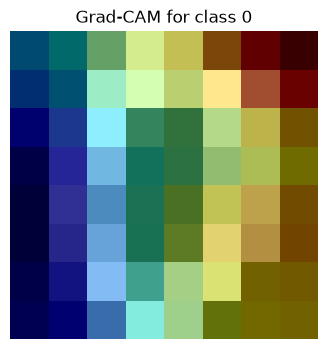

In [4]:
import torch.nn.functional as F
activations={}; gradients={}
def capture_feature(module,inputs,output):
    activations['map']=output
    output.register_hook(lambda grad: gradients.__setitem__('map',grad))
hook=m.conv2.register_forward_hook(capture_feature)
m.zero_grad(); scores=m(sample); target_class=scores.argmax(1).item(); scores[0,target_class].backward()
hook.remove()
feature=activations['map']; grad=gradients['map']; channel_weights=grad.mean(dim=(2,3),keepdim=True)
cam=torch.relu((channel_weights*feature).sum(dim=1,keepdim=True))
cam=F.interpolate(cam,size=sample.shape[-2:],mode='bilinear',align_corners=False)[0,0].detach().cpu()
cam=(cam-cam.min())/(cam.max()-cam.min()+1e-8)
image=sample[0,0].detach().cpu()
fig,ax=plt.subplots(figsize=(4,4)); ax.imshow(image,cmap='gray'); ax.imshow(cam,cmap='jet',alpha=.45); ax.set_title(f'Grad-CAM for class {target_class}'); ax.axis('off'); plt.show()
